<a href="https://colab.research.google.com/github/Shibainulove/6070-001-202630/blob/main/Assignments/Second/Case_Study_2_Internet_Sales_Qingan_Xu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Adventure Works Internet Sales: Analysis and Growth Strategy

**Case Study Report, Assignment 2 (MSSP 6070)** · Qingan Xu · November 2026

This notebook holds the analysis behind the written case study report submitted with it (*Case Study Report - Adventure Works Internet Sales - Qingan Xu*). It reproduces every number, table and figure in the report.

**Scenario.** As an analyst for Adventure Works Bicycle Company, I analyze the company's Internet sales (`InternetSales.csv`, 60,398 order lines from 29 December 2010 to 28 January 2014) and recommend a strategy for leadership to grow them.

| Required question | Answered in |
|---|---|
| 1. What are the Internet sales of Adventure Works by year for each country region? | Section 5 |
| 2. Summary statistics, including minimum, maximum and standard deviation, for yearly income by gender and country region | Section 7 |
| 3. What is the average price of the product category that generates the most sales? | Section 6, with sales by year and product category |
| 4. Does owning a home make a difference in sales? | Section 8 |
| Recommended strategy for growing Internet sales | Sections 9–11 |

*The assignment describes this data set as fictitious and provided for learning only, so the results are illustrative.*

**How to run it.** In Jupyter, choose *Kernel → Restart Kernel and Run All Cells*; in Google Colab, choose *Runtime → Run all*. No setup, passwords or file paths are needed:

- If `InternetSales.csv` is in the same folder as the notebook, that copy is used.
- If it is not, the loading cell in Section 2 downloads the same file (26 MB) from this project's public GitHub repository and confirms that it is identical to the file analyzed in the report.
- The code uses only pandas, NumPy, Matplotlib and SciPy, which come with Anaconda and Google Colab. It has been run from top to bottom with Python 3.9 (pandas 1.5, Matplotlib 3.5) and Python 3.14 (pandas 3.1, Matplotlib 3.11).

Each chart is also saved as a PNG file in a `figures/` folder next to the notebook.

## 1. Setup

In [1]:
import hashlib
import re
import shutil
import ssl
import sys
import urllib.error
import urllib.request
from pathlib import Path

import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import scipy
from scipy import stats

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# Chart style: quiet grey for context and one blue accent for the point each chart makes
ACCENT, GREY, INK, MUTED = "#2a78d6", "#b4b2ab", "#0b0b0b", "#52514e"
BLUES = ["#9ec5f4", "#5598e7", "#1c5cab"]  # ordered shades for 2011, 2012, 2013
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "savefig.facecolor": "white",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__} | scipy {scipy.__version__}")

Python 3.14.8 | pandas 3.1.1 | numpy 2.5.4 | matplotlib 3.11.2 | scipy 1.18.1


## 2. Load the data

The loader uses `InternetSales.csv` from the notebook's folder or, if the file is missing, downloads it from this project's GitHub repository. A SHA-256 fingerprint then confirms that the file is the one analyzed in the report.

The file is saved in Latin-1 (ISO-8859-1) encoding because some names and addresses contain accented characters (for example *München* and *Sèvres*), so it is read with `encoding="latin-1"`.

In [2]:
DATA_FILE = Path("InternetSales.csv")  # looked for in the notebook's folder
DATA_URL = ("https://raw.githubusercontent.com/Shibainulove/6070-001-202630/main/"
            "Assignments/Second/InternetSales.csv")
DATA_SHA256 = "e61fa8ba71b4b30fc993aef8d34e890075db3029f3582732a76fd8f07ecd5fb3"  # the file analyzed in the report


def sha256_of(path):
    """Return the SHA-256 fingerprint of a file."""
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def download(url, dest):
    """Save url to dest. If Python cannot find its SSL certificates (common on macOS), retry with certifi's."""
    contexts = [None]
    try:
        import certifi
        contexts.append(ssl.create_default_context(cafile=certifi.where()))
    except ImportError:
        pass
    for attempt, context in enumerate(contexts, start=1):
        try:
            with urllib.request.urlopen(url, timeout=60, context=context) as response, open(dest, "wb") as out:
                shutil.copyfileobj(response, out)
            return
        except urllib.error.URLError as err:
            if attempt == len(contexts) or not isinstance(err.reason, ssl.SSLError):
                raise


if DATA_FILE.exists():
    print(f"Using {DATA_FILE} from the notebook's folder")
else:
    print(f"{DATA_FILE} is not in the notebook's folder, so it is being downloaded from GitHub (26 MB)...")
    try:
        download(DATA_URL, DATA_FILE)
        print(f"Saved {DATA_FILE} in the notebook's folder")
    except Exception as err:
        DATA_FILE.unlink(missing_ok=True)  # remove a partial download
        try:
            from google.colab import files  # only available inside Google Colab
        except ImportError:
            raise RuntimeError(f"The download failed ({err}). Save InternetSales.csv from {DATA_URL} "
                               "in the same folder as this notebook and run the notebook again.") from None
        print(f"The download failed ({err}). Choose InternetSales.csv in the upload box below.")
        uploaded = files.upload()
        DATA_FILE.write_bytes(next(iter(uploaded.values())))

if sha256_of(DATA_FILE) == DATA_SHA256:
    print("Fingerprint check passed: this is the file analyzed in the report")
else:
    print("Warning: this file differs from the one analyzed in the report, so some results may differ")

raw = pd.read_csv(DATA_FILE, encoding="latin-1", low_memory=False)
print(f"Loaded {len(raw):,} order lines and {raw.shape[1]} columns")

InternetSales.csv is not in the notebook's folder, so it is being downloaded from GitHub (26 MB)...


Saved InternetSales.csv in the notebook's folder
Fingerprint check passed: this is the file analyzed in the report
Loaded 60,398 order lines and 60 columns


In [3]:
preview_cols = ["SalesOrderNumber", "OrderDate", "CustomerKey", "EnglishCountryRegionName", "Gender",
                "YearlyIncome", "HouseOwnerFlag", "EnglishProductName", "OrderQuantity", "UnitPrice", "SalesAmount"]
raw[preview_cols].head()

,SalesOrderNumber,OrderDate,CustomerKey,EnglishCountryRegionName,Gender,YearlyIncome,HouseOwnerFlag,EnglishProductName,OrderQuantity,UnitPrice,SalesAmount
0,SO43793,1/19/2011,11000,Australia,M,90000,1,"Mountain-100 Silver, 38",1,3399.99,3399.99
1,SO51522,1/18/2013,11000,Australia,M,90000,1,"Mountain-200 Silver, 38",1,2319.99,2319.99
2,SO51522,1/18/2013,11000,Australia,M,90000,1,Fender Set - Mountain,1,21.98,21.98
3,SO57418,5/3/2013,11000,Australia,M,90000,1,"Touring-1000 Blue, 46",1,2384.07,2384.07
4,SO57418,5/3/2013,11000,Australia,M,90000,1,Touring Tire,1,28.99,28.99


## 3. Audit the data

Before analyzing, check what each row represents, which fields are empty, and whether the amounts behave as expected.

In [4]:
missing = raw.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False).to_frame("Missing values")
missing["Share of rows"] = missing["Missing values"] / len(raw)
missing.style.format({"Missing values": "{:,}", "Share of rows": "{:.1%}"})

,Missing values,Share of rows
CarrierTrackingNumber,"60,398",100.0%
CustomerPONumber,"60,398",100.0%
Suffix,"60,392",100.0%
Title,"60,091",99.5%
AddressLine2,"59,293",98.2%
MiddleName,"25,495",42.2%


In [5]:
checks = pd.Series({
    "Order lines (rows)": f"{len(raw):,}",
    "Sales orders": f"{raw['SalesOrderNumber'].nunique():,}",
    "Customers": f"{raw['CustomerKey'].nunique():,}",
    "Products (product keys)": f"{raw['ProductKey'].nunique():,}",
    "Country regions": f"{raw['EnglishCountryRegionName'].nunique()}",
    "Duplicate row IDs": f"{raw['ID'].duplicated().sum()}",
    "Column 'CustomerKey.1' is identical to 'CustomerKey'": str((raw["CustomerKey"] == raw["CustomerKey.1"]).all()),
    "Order quantity is always 1": str((raw["OrderQuantity"] == 1).all()),
    "Lines with a discount": f"{(raw['DiscountAmount'] != 0).sum()}",
    "SalesAmount = UnitPrice x OrderQuantity": str(np.allclose(raw["SalesAmount"], raw["UnitPrice"] * raw["OrderQuantity"])),
    "Each product has one price in every currency": str((raw.groupby("ProductKey")["UnitPrice"].nunique() == 1).all()),
}, name="Result")
checks.to_frame()

,Result
Order lines (rows),"60,398"
Sales orders,"27,659"
Customers,"18,484"
Products (product keys),158
Country regions,6
Duplicate row IDs,0
Column 'CustomerKey.1' is identical to 'CustomerKey',True
Order quantity is always 1,True
Lines with a discount,0
SalesAmount = UnitPrice x OrderQuantity,True


**What the audit shows, and the limitations it implies**

- Each row is one **order line** (one product on one order). There are 60,398 lines, 27,659 orders, 18,484 customers and 158 products in six country regions.
- `CarrierTrackingNumber` and `CustomerPONumber` are completely empty; `Suffix`, `Title` and `AddressLine2` are almost entirely blank, and `MiddleName` is missing for 42% of rows. None is needed here.
- `CustomerKey` appears twice in the file (pandas renames the copy `CustomerKey.1`). The copy is identical, so it is dropped.
- Every line has a quantity of 1 and no discount, so `SalesAmount` equals the unit price. Sales exclude tax and freight.
- A product has the same price whatever currency the customer uses, so all amounts are treated as **US dollars**.
- The file has **no product-category column**, and nothing on website visitors who did not buy, marketing spend, returns or costs other than product cost. Every customer in the file is a buyer.

## 4. Prepare the data

Convert dates, add order year and month, and compute gross profit (sales minus product cost).

In [6]:
sales = raw.drop(columns=["CustomerKey.1"]).rename(columns={"EnglishCountryRegionName": "Country"})
for col in ["OrderDate", "DueDate", "ShipDate", "BirthDate", "DateFirstPurchase"]:
    sales[col] = pd.to_datetime(sales[col], format="%m/%d/%Y")
sales["Year"] = sales["OrderDate"].dt.year
sales["Month"] = sales["OrderDate"].dt.to_period("M")
sales["GrossProfit"] = sales["SalesAmount"] - sales["TotalProductCost"]

coverage = sales.groupby("Year").agg(
    FirstOrder=("OrderDate", "min"), LastOrder=("OrderDate", "max"),
    DaysWithOrders=("OrderDate", "nunique"), OrderLines=("ID", "size"), Sales=("SalesAmount", "sum"))
coverage.style.format({"FirstOrder": "{:%Y-%m-%d}", "LastOrder": "{:%Y-%m-%d}",
                       "OrderLines": "{:,}", "Sales": "${:,.0f}"})

,FirstOrder,LastOrder,DaysWithOrders,OrderLines,Sales
Year,,,,,
2010,2010-12-29,2010-12-31,3,14,"$43,421"
2011,2011-01-01,2011-12-31,362,"2,216","$7,075,526"
2012,2012-01-01,2012-12-31,366,"3,397","$5,842,485"
2013,2013-01-01,2013-12-31,365,"52,801","$16,351,550"
2014,2014-01-01,2014-01-28,28,"1,970","$45,695"


**Partial years.** 2010 covers only 29–31 December and 2014 only 1–28 January (and January 2014 has no bike sales at all). Year-over-year comparisons therefore use the three full years, **2011–2013**; 2010 and 2014 are shown but flagged.

### Product categories

The file names each product but has no category. Each product is assigned to Adventure Works' product hierarchy from its name: bike models are named `Mountain-`, `Road-` or `Touring-` followed by a model number, and every other product contains a keyword that identifies its subcategory. This assignment matches Microsoft's own hierarchy (`DimProduct` → `DimProductSubcategory` → `DimProductCategory` in the AdventureWorksDW sample) for all 158 product keys.

In [7]:
BIKE_MODEL = re.compile(r"^(Mountain|Road|Touring)-\d")  # e.g. "Road-150 Red, 62"
KEYWORDS = [  # (word in the product name, subcategory, category)
    ("Helmet", "Helmets", "Accessories"),
    ("Bottle", "Bottles and Cages", "Accessories"),
    ("Tire", "Tires and Tubes", "Accessories"),
    ("Patch Kit", "Tires and Tubes", "Accessories"),
    ("Fender", "Fenders", "Accessories"),
    ("Hydration Pack", "Hydration Packs", "Accessories"),
    ("Hitch Rack", "Bike Racks", "Accessories"),
    ("Bike Stand", "Bike Stands", "Accessories"),
    ("Bike Wash", "Cleaners", "Accessories"),
    ("Cap", "Caps", "Clothing"),
    ("Jersey", "Jerseys", "Clothing"),
    ("Gloves", "Gloves", "Clothing"),
    ("Vest", "Vests", "Clothing"),
    ("Shorts", "Shorts", "Clothing"),
    ("Socks", "Socks", "Clothing"),
]


def classify_product(name):
    """Return (subcategory, category) for an Adventure Works product name."""
    match = BIKE_MODEL.match(name)
    if match:
        return f"{match.group(1)} Bikes", "Bikes"
    for keyword, subcategory, category in KEYWORDS:
        if keyword in name:
            return subcategory, category
    return "Unmapped", "Unmapped"


product_map = sales[["ProductKey", "EnglishProductName"]].drop_duplicates().reset_index(drop=True)
product_map[["Subcategory", "Category"]] = [classify_product(name) for name in product_map["EnglishProductName"]]
assert (product_map["Category"] != "Unmapped").all(), "Some products were not classified"
sales = sales.merge(product_map[["ProductKey", "Subcategory", "Category"]], on="ProductKey", how="left")

product_map.groupby(["Category", "Subcategory"]).agg(
    Products=("ProductKey", "size"), Example=("EnglishProductName", "first"))

Products                         Example
Category    Subcategory                                                
Accessories Bike Racks                1             Hitch Rack - 4-Bike
            Bike Stands               1          All-Purpose Bike Stand
            Bottles and Cages         3           Water Bottle - 30 oz.
            Cleaners                  1           Bike Wash - Dissolver
            Fenders                   1           Fender Set - Mountain
            Helmets                   3           Sport-100 Helmet, Red
            Hydration Packs           1         Hydration Pack - 70 oz.
            Tires and Tubes          11                    Touring Tire
Bikes       Mountain Bikes           34         Mountain-100 Silver, 38
            Road Bikes               60              Road-750 Black, 44
            Touring Bikes            22           Touring-1000 Blue, 46
Clothing    Caps                      1                    AWC Logo Cap
            Gloves                    3           Half-Finger Gloves, M
            Jerseys                   8  Short-Sleeve Classic Jersey, S
            Shorts                    3      Women's Mountain Shorts, M
            Socks                     2                 Racing Socks, L
            Vests                     3                 Classic Vest, M

### Order-level and customer-level tables

Questions about customers (income, home ownership, repeat purchases) must count **each customer once**. The order-line file repeats a customer's profile on every line, so two summary tables are built: one row per order and one row per customer.

In [8]:
flags = sales.assign(HasBike=sales["Category"].eq("Bikes"),
                     HasAccessory=sales["Category"].eq("Accessories"),
                     HasClothing=sales["Category"].eq("Clothing"))
orders = (flags.groupby("SalesOrderNumber")
          .agg(CustomerKey=("CustomerKey", "first"), Country=("Country", "first"), OrderDate=("OrderDate", "first"),
               Sales=("SalesAmount", "sum"), GrossProfit=("GrossProfit", "sum"), Lines=("ID", "size"),
               HasBike=("HasBike", "max"), HasAccessory=("HasAccessory", "max"), HasClothing=("HasClothing", "max"))
          .reset_index()
          .sort_values(["CustomerKey", "OrderDate", "SalesOrderNumber"], ignore_index=True))
orders["Year"] = orders["OrderDate"].dt.year
orders["OrderNumber"] = orders.groupby("CustomerKey").cumcount() + 1  # 1 = the customer's first order

profile_cols = ["Country", "Gender", "YearlyIncome", "HouseOwnerFlag", "MaritalStatus", "TotalChildren",
                "NumberChildrenAtHome", "EnglishEducation", "EnglishOccupation", "NumberCarsOwned",
                "CommuteDistance", "BirthDate", "DateFirstPurchase"]
assert (sales.groupby("CustomerKey")[profile_cols].nunique() == 1).all().all()  # one profile per customer
customers = sales.drop_duplicates("CustomerKey").set_index("CustomerKey")[profile_cols]
customers = customers.join(orders.groupby("CustomerKey").agg(
    Sales=("Sales", "sum"), GrossProfit=("GrossProfit", "sum"),
    Orders=("SalesOrderNumber", "size"), BoughtBike=("HasBike", "max")))
customers["FirstOrderHadBike"] = orders[orders["OrderNumber"] == 1].set_index("CustomerKey")["HasBike"]
customers["FirstYear"] = customers["DateFirstPurchase"].dt.year
customers["Age"] = ((sales["OrderDate"].max() - customers["BirthDate"]).dt.days // 365.25).astype(int)

print(f"{len(orders):,} orders and {len(customers):,} customers")
print(f"DateFirstPurchase equals each customer's first order date: "
      f"{customers['DateFirstPurchase'].eq(orders.groupby('CustomerKey')['OrderDate'].min()).all()}")

27,659 orders and 18,484 customers
DateFirstPurchase equals each customer's first order date: True


## 5. Question 1: Internet sales by year for each country region

In [9]:
country_year = sales.pivot_table(index="Country", columns="Year", values="SalesAmount",
                                 aggfunc="sum", fill_value=0, margins=True, margins_name="Total")
row_order = country_year.drop(index="Total").sort_values("Total", ascending=False).index.tolist() + ["Total"]
country_year = country_year.loc[row_order]
country_year["Share"] = country_year["Total"] / country_year.loc["Total", "Total"]
country_year.style.format("${:,.0f}", subset=list(country_year.columns[:-1])).format("{:.1%}", subset=["Share"])

Year,2010,2011,2012,2013,2014,Total,Share
Country,,,,,,,
United States,"$14,834","$2,458,285","$1,437,049","$5,462,079","$17,543","$9,389,790",32.0%
Australia,"$20,910","$2,563,732","$2,128,407","$4,339,443","$8,508","$9,061,001",30.9%
United Kingdom,$699,"$550,591","$712,701","$2,124,007","$3,714","$3,391,712",11.6%
Germany,$0,"$520,500","$608,658","$1,761,876","$3,278","$2,894,312",9.9%
France,"$3,400","$410,845","$648,066","$1,578,512","$3,195","$2,644,018",9.0%
Canada,"$3,578","$571,572","$307,605","$1,085,633","$9,458","$1,977,845",6.7%
Total,"$43,421","$7,075,526","$5,842,485","$16,351,550","$45,695","$29,358,677",100.0%


In [10]:
growth = pd.DataFrame({
    "2012 vs 2011": country_year[2012] / country_year[2011] - 1,
    "2013 vs 2012": country_year[2013] / country_year[2012] - 1,
})
growth.style.format("{:+.1%}")

,2012 vs 2011,2013 vs 2012
Country,,
United States,-41.5%,+280.1%
Australia,-17.0%,+103.9%
United Kingdom,+29.4%,+198.0%
Germany,+16.9%,+189.5%
France,+57.7%,+143.6%
Canada,-46.2%,+252.9%
Total,-17.4%,+179.9%


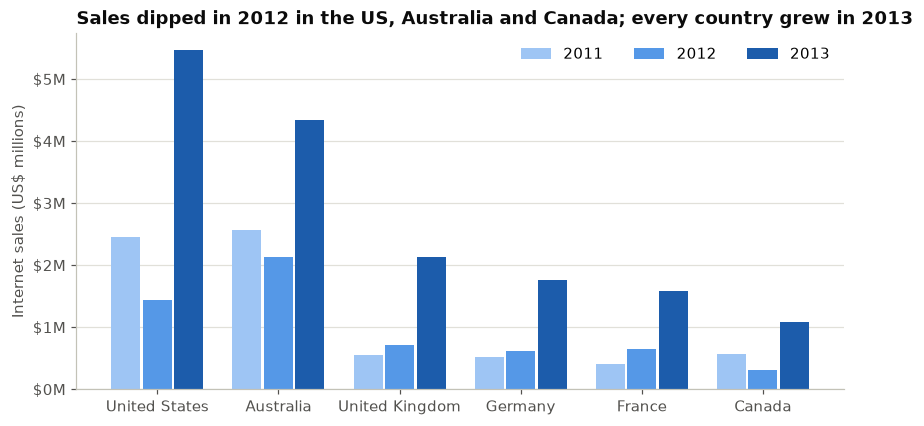

In [11]:
FULL_YEARS = [2011, 2012, 2013]
plot_data = country_year.drop(index="Total")[FULL_YEARS] / 1e6
x = np.arange(len(plot_data))
width = 0.26
fig, ax = plt.subplots(figsize=(9, 4.2))
for i, (year, color) in enumerate(zip(FULL_YEARS, BLUES)):
    ax.bar(x + (i - 1) * width, plot_data[year], width=width * 0.92, color=color, label=str(year))
ax.set_xticks(x)
ax.set_xticklabels(plot_data.index)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}M"))
ax.set_ylabel("Internet sales (US$ millions)")
ax.set_title("Sales dipped in 2012 in the US, Australia and Canada; every country grew in 2013")
ax.legend(ncol=3, loc="upper right")
fig.savefig(FIG_DIR / "sales_by_country_and_year.png")
plt.show()

**Answer to Question 1.** Internet sales total **\$29.36 million** from 29 December 2010 to 28 January 2014. The **United States (\$9.39M, 32.0%)** and **Australia (\$9.06M, 30.9%)** together account for 63% of sales; the United Kingdom, Germany, France and Canada follow. Total sales **fell 17.4% in 2012** (\$7.08M to \$5.84M), with the US (−41.5%), Canada (−46.2%) and Australia (−17.0%) declining while France, the UK and Germany grew. Sales then **rose 179.9% in 2013** to \$16.35M, and every country at least doubled. The 2010 and 2014 columns cover only a few days each.

## 6. Sales by year and product category, and Question 3: average price of the top category

In [12]:
category_year = sales.pivot_table(index="Category", columns="Year", values="SalesAmount",
                                  aggfunc="sum", fill_value=0, margins=True, margins_name="Total")
category_year = category_year.loc[["Bikes", "Accessories", "Clothing", "Total"]]
category_year["Share"] = category_year["Total"] / category_year.loc["Total", "Total"]
category_year.style.format("${:,.0f}", subset=list(category_year.columns[:-1])).format("{:.1%}", subset=["Share"])

Year,2010,2011,2012,2013,2014,Total,Share
Category,,,,,,,
Bikes,"$43,421","$7,075,526","$5,839,695","$15,359,502",$0,"$28,318,145",96.5%
Accessories,$0,$0,"$2,147","$668,242","$30,371","$700,760",2.4%
Clothing,$0,$0,$643,"$323,806","$15,323","$339,773",1.2%
Total,"$43,421","$7,075,526","$5,842,485","$16,351,550","$45,695","$29,358,677",100.0%


In [13]:
category_summary = sales.groupby("Category").agg(
    Sales=("SalesAmount", "sum"), UnitsSold=("OrderQuantity", "sum"), AvgUnitPrice=("UnitPrice", "mean"),
    GrossProfit=("GrossProfit", "sum"), FirstSold=("OrderDate", "min"))
category_summary["ShareOfSales"] = category_summary["Sales"] / category_summary["Sales"].sum()
category_summary["GrossMargin"] = category_summary["GrossProfit"] / category_summary["Sales"]
category_summary = category_summary.sort_values("Sales", ascending=False)
category_summary.style.format({"Sales": "${:,.0f}", "UnitsSold": "{:,}", "AvgUnitPrice": "${:,.2f}",
                               "GrossProfit": "${:,.0f}", "FirstSold": "{:%Y-%m-%d}",
                               "ShareOfSales": "{:.1%}", "GrossMargin": "{:.1%}"})

,Sales,UnitsSold,AvgUnitPrice,GrossProfit,FirstSold,ShareOfSales,GrossMargin
Category,,,,,,,
Bikes,"$28,318,145","15,205","$1,862.42","$11,505,797",2010-12-29,96.5%,40.6%
Accessories,"$700,760","36,092",$19.42,"$438,675",2012-12-28,2.4%,62.6%
Clothing,"$339,773","9,101",$37.33,"$136,413",2012-12-28,1.2%,40.1%


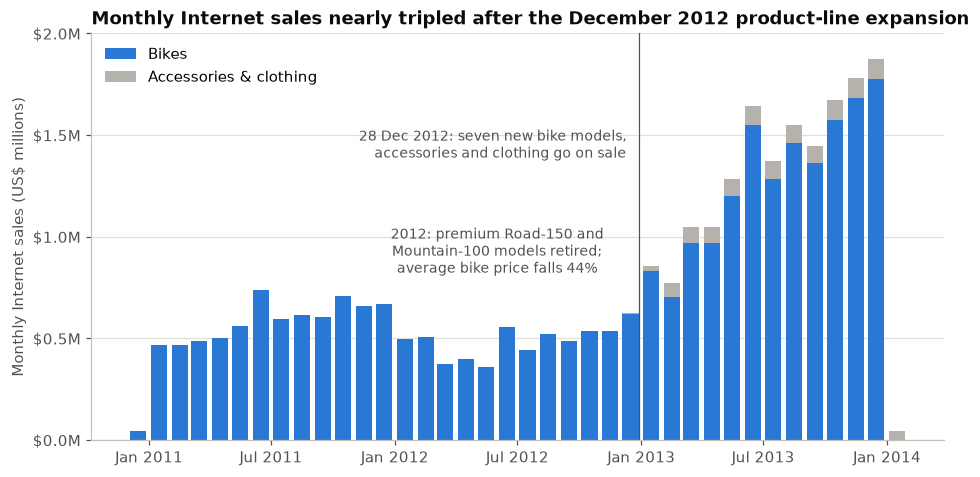

In [14]:
monthly = (sales.assign(Group=np.where(sales["Category"].eq("Bikes"), "Bikes", "Accessories & clothing"))
           .pivot_table(index="Month", columns="Group", values="SalesAmount", aggfunc="sum", fill_value=0))
centers = monthly.index.to_timestamp() + pd.Timedelta(days=15)  # draw each month's bar mid-month
bikes_m, other_m = monthly["Bikes"] / 1e6, monthly["Accessories & clothing"] / 1e6
launch = pd.Timestamp("2012-12-28")

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(centers, bikes_m, width=24, color=ACCENT, label="Bikes")
ax.bar(centers, other_m, width=24, bottom=bikes_m, color=GREY, label="Accessories & clothing")
ax.axvline(launch, color=MUTED, linewidth=0.8)
ax.annotate("28 Dec 2012: seven new bike models,\naccessories and clothing go on sale",
            xy=(launch, 1.45), xytext=(-8, 0), textcoords="offset points",
            ha="right", va="center", fontsize=9, color=MUTED)
ax.annotate("2012: premium Road-150 and\nMountain-100 models retired;\naverage bike price falls 44%",
            xy=(pd.Timestamp("2012-06-01"), 0.80), ha="center", va="bottom", fontsize=9, color=MUTED)
ax.set_ylim(0, 2.0)
ax.yaxis.set_major_locator(mticker.MultipleLocator(0.5))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:.1f}M"))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylabel("Monthly Internet sales (US$ millions)")
ax.set_title("Monthly Internet sales nearly tripled after the December 2012 product-line expansion")
ax.legend(loc="upper left")
fig.savefig(FIG_DIR / "fig1_monthly_sales_by_category.png")
plt.show()

In [15]:
bike_lines = sales[sales["Category"] == "Bikes"]
bike_years = (bike_lines[bike_lines["Year"].isin(FULL_YEARS)].groupby("Year")
              .agg(BikesSold=("OrderQuantity", "sum"), AvgPrice=("UnitPrice", "mean"), BikeSales=("SalesAmount", "sum")))
for col in ["BikesSold", "AvgPrice", "BikeSales"]:
    bike_years[col + "Change"] = bike_years[col] / bike_years[col].shift() - 1
bike_years.style.format({"BikesSold": "{:,}", "AvgPrice": "${:,.2f}", "BikeSales": "${:,.0f}",
                         "BikesSoldChange": "{:+.1%}", "AvgPriceChange": "{:+.1%}", "BikeSalesChange": "{:+.1%}"},
                        na_rep="")

,BikesSold,AvgPrice,BikeSales,BikesSoldChange,AvgPriceChange,BikeSalesChange
Year,,,,,,
2011,"2,216","$3,192.93","$7,075,526",,,
2012,"3,269","$1,786.39","$5,839,695",+47.5%,-44.1%,-17.5%
2013,"9,706","$1,582.48","$15,359,502",+196.9%,-11.4%,+163.0%


In [16]:
# When was each bike model on sale online? (model = product name without colour and frame size)
model_life = (bike_lines.assign(Model=bike_lines["EnglishProductName"].str.extract(r"^(\w+-\d+(?:-W)?)", expand=False))
              .groupby("Model")
              .agg(FirstSold=("OrderDate", "min"), LastSold=("OrderDate", "max"), BikesSold=("OrderQuantity", "sum"),
                   AvgPrice=("UnitPrice", "mean"))
              .sort_values(["FirstSold", "AvgPrice"], ascending=[True, False]))
model_life.style.format({"FirstSold": "{:%Y-%m-%d}", "LastSold": "{:%Y-%m-%d}", "BikesSold": "{:,}",
                         "AvgPrice": "${:,.2f}"})

,FirstSold,LastSold,BikesSold,AvgPrice
Model,,,,
Road-150,2010-12-29,2011-12-28,"1,551","$3,578.27"
Mountain-100,2010-12-29,2011-12-28,396,"$3,386.67"
Road-650,2010-12-29,2012-12-27,852,$757.49
Road-250,2011-12-29,2013-12-28,"1,903","$2,339.08"
Mountain-200,2011-12-29,2013-12-28,"3,552","$2,232.40"
Road-550-W,2011-12-29,2013-12-28,"1,390","$1,089.66"
Touring-1000,2012-12-28,2013-12-28,"1,255","$2,384.07"
Road-350-W,2012-12-28,2013-12-27,929,"$1,700.99"
Touring-2000,2012-12-28,2013-12-28,372,"$1,214.85"


**Sales by year and category.** Bikes generate **96.5%** of Internet sales (\$28.32M). Until late December 2012 the online store sold only bikes; accessories and clothing went on sale on 28 December 2012, alongside the new Touring range. In 2013 they sold 43,095 units but added only \$0.99M, because their average prices are \$19.42 (accessories) and \$37.33 (clothing). Accessories earn the highest gross margin (62.6%, against 40.6% for bikes).

**Why 2012 fell.** The online bike range was renewed twice. At the end of December 2011 the premium Road-150 (\$3,578.27) and Mountain-100 (about \$3,400) were replaced by cheaper models (Mountain-200, Road-250, Road-550-W). In 2012 Adventure Works therefore sold 47.5% more bikes than in 2011, but the average bike price fell 44.1% (from \$3,192.93 to \$1,786.39) and bike revenue dropped 17.5%. Cheaper bikes brought more buyers, not more revenue. On 28–30 December 2012 seven new models (Road-350-W, Road-750, Mountain-400-W, Mountain-500 and the three Touring models) arrived together with accessories and clothing, and sales nearly tripled in 2013.

In [17]:
top_category = category_summary["Sales"].idxmax()
top_lines = sales[sales["Category"] == top_category]
avg_price = top_lines["SalesAmount"].sum() / top_lines["OrderQuantity"].sum()
catalog_avg = top_lines.drop_duplicates("ProductKey")["UnitPrice"].mean()

print(f"Top category: {top_category} ({category_summary.loc[top_category, 'ShareOfSales']:.1%} of Internet sales)")
print(f"Average price per bike sold: ${avg_price:,.2f} "
      f"({top_lines['OrderQuantity'].sum():,} bikes, ${top_lines['SalesAmount'].sum():,.2f} in sales)")
print(f"Average list price across the {top_lines['ProductKey'].nunique()} bike products: ${catalog_avg:,.2f}")
top_lines["UnitPrice"].describe().to_frame("Bike unit price (US$)").T.style.format("{:,.2f}")

Top category: Bikes (96.5% of Internet sales)
Average price per bike sold: $1,862.42 (15,205 bikes, $28,318,144.65 in sales)
Average list price across the 116 bike products: $1,542.80


,count,mean,std,min,25%,50%,75%,max
Bike unit price (US$),"15,205.00","1,862.42",944.12,539.99,782.99,"2,071.42","2,384.07","3,578.27"


In [18]:
price_table = top_lines.groupby("Subcategory").agg(
    UnitsSold=("OrderQuantity", "sum"), Sales=("SalesAmount", "sum"), AvgPrice=("UnitPrice", "mean"),
    LowestPrice=("UnitPrice", "min"), HighestPrice=("UnitPrice", "max"))
all_bikes = pd.DataFrame({"UnitsSold": [top_lines["OrderQuantity"].sum()], "Sales": [top_lines["SalesAmount"].sum()],
                          "AvgPrice": [avg_price], "LowestPrice": [top_lines["UnitPrice"].min()],
                          "HighestPrice": [top_lines["UnitPrice"].max()]}, index=["All bikes"])
price_table = pd.concat([price_table, all_bikes])
price_table.style.format({"UnitsSold": "{:,}", "Sales": "${:,.0f}", "AvgPrice": "${:,.2f}",
                          "LowestPrice": "${:,.2f}", "HighestPrice": "${:,.2f}"})

,UnitsSold,Sales,AvgPrice,LowestPrice,HighestPrice
Mountain Bikes,"4,970","$9,952,760","$2,002.57",$539.99,"$3,399.99"
Road Bikes,"8,068","$14,520,584","$1,799.77",$539.99,"$3,578.27"
Touring Bikes,"2,167","$3,844,801","$1,774.25",$742.35,"$2,384.07"
All bikes,"15,205","$28,318,145","$1,862.42",$539.99,"$3,578.27"


**Answer to Question 3.** **Bikes** generate the most sales. The average price of a bike sold online is **\$1,862.42** (\$28,318,144.65 across 15,205 bikes; every order line is one unit with no discount). Prices range from \$539.99 to \$3,578.27 with a standard deviation of \$944.12. Mountain bikes average \$2,002.57, road bikes \$1,799.77 and touring bikes \$1,774.25. Averaged over the 116 bike products in the catalog, without weighting by sales, the list price is \$1,542.80.

## 7. Question 2: Yearly income by gender and country region

Income is a customer attribute, so the statistics count each of the 18,484 customers once.

In [19]:
income_stats = (customers.groupby(["Country", "Gender"])["YearlyIncome"]
                .agg(Customers="count", Mean="mean", Median="median", StdDev="std", Min="min", Max="max"))
income_stats.style.format({"Customers": "{:,}", "Mean": "${:,.0f}", "Median": "${:,.0f}",
                           "StdDev": "${:,.0f}", "Min": "${:,.0f}", "Max": "${:,.0f}"})

In [20]:
income_country = (customers.groupby("Country")["YearlyIncome"]
                  .agg(Customers="count", Mean="mean", Median="median", StdDev="std", Min="min", Max="max")
                  .sort_values("Mean", ascending=False))
gender_mix = pd.crosstab(customers["Country"], customers["Gender"])
income_country["FemaleShare"] = gender_mix["F"] / gender_mix.sum(axis=1)
mean_by_gender = customers.pivot_table(index="Country", columns="Gender", values="YearlyIncome", aggfunc="mean")
income_country["MeanGap(M-F)"] = mean_by_gender["M"] - mean_by_gender["F"]
income_country.style.format({"Customers": "{:,}", "Mean": "${:,.0f}", "Median": "${:,.0f}", "StdDev": "${:,.0f}",
                             "Min": "${:,.0f}", "Max": "${:,.0f}", "FemaleShare": "{:.1%}", "MeanGap(M-F)": "{:+,.0f}"})

,Customers,Mean,Median,StdDev,Min,Max,FemaleShare,MeanGap(M-F)
Country,,,,,,,,
Australia,"3,591","$64,339","$70,000","$31,830","$10,000","$170,000",49.5%,"-1,872"
United States,"7,819","$63,617","$60,000","$25,706","$10,000","$170,000",49.7%,+676
Canada,"1,571","$57,167","$60,000","$20,252","$10,000","$170,000",48.8%,"+1,293"
United Kingdom,"1,913","$52,169","$30,000","$48,432","$10,000","$170,000",48.8%,-29
Germany,"1,780","$42,944","$30,000","$35,494","$10,000","$130,000",49.1%,"-1,702"
France,"1,810","$35,762","$30,000","$27,277","$10,000","$110,000",49.3%,+831


In [21]:
# Sensitivity check: computing the same means on order lines would count frequent buyers many times
line_level = sales.groupby(["Country", "Gender"])["YearlyIncome"].mean()
comparison = pd.DataFrame({"Per customer": income_stats["Mean"], "Per order line": line_level})
comparison["Difference"] = comparison["Per order line"] - comparison["Per customer"]
comparison.style.format({"Per customer": "${:,.0f}", "Per order line": "${:,.0f}", "Difference": "{:+,.0f}"})

**Answer to Question 2.** Customers are split almost evenly by gender in every country (48.8%–49.7% female), and within each country men's and women's average incomes differ by less than \$2,000. Income differs far more **between countries**: Australia (mean \$64,339) and the United States (\$63,617) have the highest incomes, followed by Canada (\$57,167), the United Kingdom (\$52,169), Germany (\$42,944) and France (\$35,762). The minimum is \$10,000 everywhere; the maximum is \$170,000 in most groups but only \$110,000 in France and \$130,000 in Germany. The United Kingdom has the widest spread (standard deviation about \$48,000) and Canada the narrowest (about \$20,000). Income is recorded in \$10,000 bands, so these statistics describe banded values. Computing the statistics on order lines instead of customers would raise every mean by \$1,500–\$4,600, because higher-income customers place more order lines.

## 8. Question 4: Does owning a home make a difference in sales?

Compare customers who own a home (`HouseOwnerFlag = 1`) with those who do not, on lifetime Internet sales per customer.

In [22]:
customers["Owner"] = customers["HouseOwnerFlag"].map({1: "Homeowner", 0: "Not a homeowner"})
home = customers.groupby("Owner").agg(
    Customers=("Sales", "size"), TotalSales=("Sales", "sum"), MeanSales=("Sales", "mean"),
    MedianSales=("Sales", "median"), OrdersPerCustomer=("Orders", "mean"), TotalOrders=("Orders", "sum"),
    BikeBuyerRate=("BoughtBike", "mean"), MeanIncome=("YearlyIncome", "mean"))
home["ShareOfCustomers"] = home["Customers"] / home["Customers"].sum()
home["ShareOfSales"] = home["TotalSales"] / home["TotalSales"].sum()
home["AvgOrderValue"] = home["TotalSales"] / home["TotalOrders"]
home = home.drop(columns="TotalOrders").loc[["Homeowner", "Not a homeowner"]]
home.style.format({"Customers": "{:,}", "TotalSales": "${:,.0f}", "MeanSales": "${:,.2f}", "MedianSales": "${:,.2f}",
                   "OrdersPerCustomer": "{:.2f}", "BikeBuyerRate": "{:.1%}", "MeanIncome": "${:,.0f}",
                   "ShareOfCustomers": "{:.1%}", "ShareOfSales": "{:.1%}", "AvgOrderValue": "${:,.2f}"})

,Customers,TotalSales,MeanSales,MedianSales,OrdersPerCustomer,BikeBuyerRate,MeanIncome,ShareOfCustomers,ShareOfSales,AvgOrderValue
Owner,,,,,,,,,,
Homeowner,"12,502","$20,385,350","$1,630.57",$342.00,1.52,49.7%,"$58,327",67.6%,69.4%,"$1,069.65"
Not a homeowner,"5,982","$8,973,327","$1,500.05",$209.96,1.44,48.9%,"$55,172",32.4%,30.6%,"$1,043.29"


In [23]:
owners = customers.loc[customers["HouseOwnerFlag"] == 1, "Sales"]
non_owners = customers.loc[customers["HouseOwnerFlag"] == 0, "Sales"]
diff = owners.mean() - non_owners.mean()
se = np.sqrt(owners.var() / len(owners) + non_owners.var() / len(non_owners))
welch = stats.ttest_ind(owners, non_owners, equal_var=False)
mwu = stats.mannwhitneyu(owners, non_owners, alternative="two-sided")
pooled_sd = np.sqrt(((len(owners) - 1) * owners.var() + (len(non_owners) - 1) * non_owners.var())
                    / (len(owners) + len(non_owners) - 2))
chi2, chi_p, _, _ = stats.chi2_contingency(pd.crosstab(customers["HouseOwnerFlag"], customers["BoughtBike"]))

print(f"Mean sales per customer: homeowners ${owners.mean():,.2f} vs non-homeowners ${non_owners.mean():,.2f}")
print(f"Difference: ${diff:,.2f} ({diff / non_owners.mean():+.1%}); 95% CI ${diff - 1.96 * se:,.0f} to ${diff + 1.96 * se:,.0f}")
print(f"Welch t-test: t = {welch.statistic:.2f}, p = {welch.pvalue:.5f}")
print(f"Mann-Whitney U test (medians/ranks): p = {mwu.pvalue:.4f}")
print(f"Effect size (Cohen's d): {diff / pooled_sd:.3f}")
print(f"Bought a bike: homeowners {customers.loc[customers['HouseOwnerFlag'] == 1, 'BoughtBike'].mean():.1%} vs "
      f"non-homeowners {customers.loc[customers['HouseOwnerFlag'] == 0, 'BoughtBike'].mean():.1%} "
      f"(chi-square p = {chi_p:.2f})")

Mean sales per customer: homeowners $1,630.57 vs non-homeowners $1,500.05
Difference: $130.51 (+8.7%); 95% CI $66 to $195
Welch t-test: t = 3.98, p = 0.00007
Mann-Whitney U test (medians/ranks): p = 0.0006
Effect size (Cohen's d): 0.061
Bought a bike: homeowners 49.7% vs non-homeowners 48.9% (chi-square p = 0.32)


In [24]:
def p_text(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"


rows = []
for country, grp in customers.groupby("Country"):
    own, non = grp.loc[grp["HouseOwnerFlag"] == 1, "Sales"], grp.loc[grp["HouseOwnerFlag"] == 0, "Sales"]
    rows.append({"Country": country, "HomeownerShare": len(own) / len(grp),
                 "MeanSalesHomeowners": own.mean(), "MeanSalesNonHomeowners": non.mean(),
                 "Difference": own.mean() - non.mean(), "WelchP": stats.ttest_ind(own, non, equal_var=False).pvalue})
home_by_country = pd.DataFrame(rows).set_index("Country").sort_values("Difference")
home_by_country.style.format({"HomeownerShare": "{:.1%}", "MeanSalesHomeowners": "${:,.0f}",
                              "MeanSalesNonHomeowners": "${:,.0f}", "Difference": "{:+,.0f}", "WelchP": p_text})

,HomeownerShare,MeanSalesHomeowners,MeanSalesNonHomeowners,Difference,WelchP
Country,,,,,
United States,70.8%,"$1,196","$1,214",-18,0.662
Australia,63.7%,"$2,536","$2,501",+35,0.687
Canada,67.2%,"$1,316","$1,142",+174,0.046
United Kingdom,66.3%,"$1,929","$1,466",+462,<0.001
Germany,66.2%,"$1,807","$1,272",+535,<0.001
France,65.0%,"$1,699","$1,019",+681,<0.001


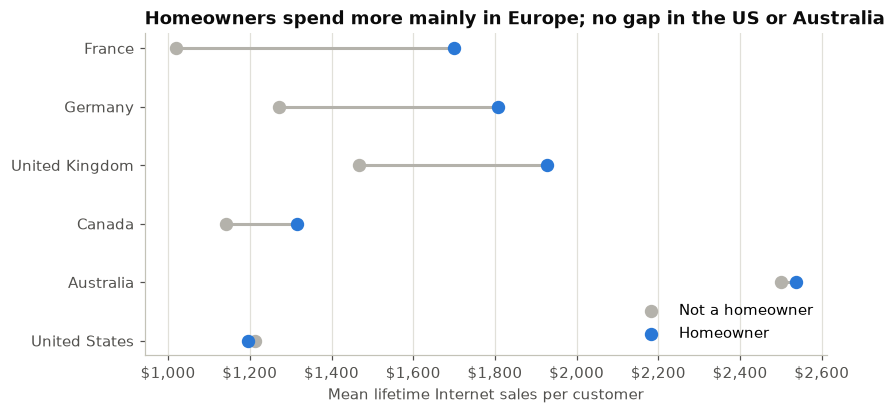

In [25]:
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(home_by_country))
ax.hlines(y, home_by_country["MeanSalesNonHomeowners"], home_by_country["MeanSalesHomeowners"], color=GREY, linewidth=2)
ax.scatter(home_by_country["MeanSalesNonHomeowners"], y, s=60, color=GREY, zorder=3, label="Not a homeowner")
ax.scatter(home_by_country["MeanSalesHomeowners"], y, s=60, color=ACCENT, zorder=3, label="Homeowner")
ax.set_yticks(y)
ax.set_yticklabels(home_by_country.index)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.grid(False, axis="y")
ax.grid(True, axis="x")
ax.set_xlabel("Mean lifetime Internet sales per customer")
ax.set_title("Homeowners spend more mainly in Europe; no gap in the US or Australia")
ax.legend(loc="lower right")
fig.savefig(FIG_DIR / "home_ownership_by_country.png")
plt.show()

Homeowners in the three European markets were more often early customers (first purchase in 2011–2012) who later bought a second bike, and customers who arrived earlier have had more time to buy again. A regression separates home ownership from those differences: it estimates lifetime sales per customer from home ownership while holding constant country, income, family, cars, education, occupation, commute distance, age and the year of first purchase. Standard errors are heteroskedasticity-robust (HC3), computed with NumPy.

In [26]:
def ols_hc3(y, X):
    """OLS coefficients with HC3 heteroskedasticity-robust standard errors."""
    Xv, yv = X.to_numpy(dtype=float), y.to_numpy(dtype=float)
    XtX_inv = np.linalg.inv(Xv.T @ Xv)
    beta = XtX_inv @ Xv.T @ yv
    resid = yv - Xv @ beta
    leverage = np.einsum("ij,jk,ik->i", Xv, XtX_inv, Xv)
    weights = (resid / (1 - leverage)) ** 2
    cov = XtX_inv @ (Xv.T * weights) @ Xv @ XtX_inv
    se = np.sqrt(np.diag(cov))
    t = beta / se
    p = 2 * stats.t.sf(np.abs(t), df=len(yv) - Xv.shape[1])
    r2 = 1 - (resid ** 2).sum() / ((yv - yv.mean()) ** 2).sum()
    return pd.DataFrame({"Coef": beta, "StdErr": se, "t": t, "p": p}, index=X.columns), r2


categorical = ["Country", "MaritalStatus", "Gender", "EnglishEducation", "EnglishOccupation", "CommuteDistance", "FirstYear"]
X = pd.concat([
    pd.Series(1.0, index=customers.index, name="Intercept"),
    customers[["HouseOwnerFlag", "YearlyIncome", "NumberCarsOwned", "NumberChildrenAtHome", "TotalChildren", "Age"]],
    pd.get_dummies(customers[categorical].astype(str), drop_first=True),
], axis=1).astype(float)
coefs, r2 = ols_hc3(customers["Sales"], X)
owner = coefs.loc["HouseOwnerFlag"]
print(f"Home-ownership effect with controls: ${owner['Coef']:,.2f} per customer "
      f"(95% CI ${owner['Coef'] - 1.96 * owner['StdErr']:,.0f} to ${owner['Coef'] + 1.96 * owner['StdErr']:,.0f}, "
      f"p = {p_text(owner['p'])}); R-squared = {r2:.3f}")
print(f"For comparison, the average customer's lifetime sales are ${customers['Sales'].mean():,.2f}")
coefs.style.format({"Coef": "{:,.2f}", "StdErr": "{:,.2f}", "t": "{:.2f}", "p": p_text})

Home-ownership effect with controls: $109.77 per customer (95% CI $70 to $149, p = <0.001); R-squared = 0.738
For comparison, the average customer's lifetime sales are $1,588.33


,Coef,StdErr,t,p
Intercept,"4,983.61",480.37,10.37,<0.001
HouseOwnerFlag,109.77,20.11,5.46,<0.001
YearlyIncome,0.01,0.00,20.18,<0.001
NumberCarsOwned,-70.56,10.90,-6.47,<0.001
NumberChildrenAtHome,-78.02,8.68,-8.99,<0.001
TotalChildren,26.26,7.64,3.43,<0.001
Age,-3.45,0.85,-4.08,<0.001
Country_Canada,-108.02,39.00,-2.77,0.006
Country_France,259.96,47.22,5.50,<0.001
Country_Germany,301.90,40.59,7.44,<0.001


**Answer to Question 4.** Owning a home makes a **statistically significant but small** difference. Homeowners are 67.6% of customers and produce 69.4% of sales. They spend **\$130.51 more per customer** on average (\$1,630.57 against \$1,500.05, or 8.7% more; Welch t-test p < 0.001), mainly because they place slightly more orders (1.52 against 1.44). The effect size is tiny (Cohen's d = 0.06), and homeowners are no more likely to buy a bike (49.7% against 48.9%, p = 0.32). There is **no difference in the United States or Australia**, which produce 63% of sales; the gap comes mainly from France, Germany and the United Kingdom (Canada's smaller gap, \$174, is borderline at p = 0.046). Holding the other customer characteristics constant, a homeowner spends about \$110 more over their lifetime, about 7% of the average customer's spending. Home ownership is therefore a weak basis for targeting compared with country, purchase history or the profile factors in Section 10. Because every customer in the file already bought something, the data cannot show whether homeowners are more likely to become customers in the first place.

## 9. Where growth comes from

The growth recommendation rests on how customers behave over time: who buys, who comes back, and what they buy when they return.

In [27]:
kpis = (orders.assign(NewCustomer=orders["OrderNumber"].eq(1))
        .groupby("Year")
        .agg(Orders=("SalesOrderNumber", "size"), ActiveCustomers=("CustomerKey", "nunique"),
             NewCustomers=("NewCustomer", "sum"), Sales=("Sales", "sum"), AvgOrderValue=("Sales", "mean"),
             LinesPerOrder=("Lines", "mean"), BikeOrders=("HasBike", "sum")))
kpis.style.format({"Orders": "{:,}", "ActiveCustomers": "{:,}", "NewCustomers": "{:,}", "Sales": "${:,.0f}",
                   "AvgOrderValue": "${:,.2f}", "LinesPerOrder": "{:.2f}", "BikeOrders": "{:,}"})

,Orders,ActiveCustomers,NewCustomers,Sales,AvgOrderValue,LinesPerOrder,BikeOrders
Year,,,,,,,
2010,14,14,14,"$43,421","$3,101.50",1.00,14
2011,"2,216","2,216","2,216","$7,075,526","$3,192.93",1.00,"2,216"
2012,"3,269","3,255","3,225","$5,842,485","$1,787.24",1.04,"3,269"
2013,"21,289","17,429","12,523","$16,351,550",$768.08,2.48,"9,706"
2014,871,834,506,"$45,695",$52.46,2.26,0


In [28]:
o13 = orders[orders["Year"] == 2013].join(customers[["FirstYear", "BoughtBike"]], on="CustomerKey")
GROUPS = ["Returning customers (first order 2010-2012)", "New in 2013: bike buyers",
          "New in 2013: accessories and clothing only"]
o13["Group"] = np.select([o13["FirstYear"] <= 2012, o13["BoughtBike"]], GROUPS[:2], default=GROUPS[2])
groups_2013 = o13.groupby("Group").agg(Customers=("CustomerKey", "nunique"), Orders=("SalesOrderNumber", "size"),
                                       Sales=("Sales", "sum")).loc[GROUPS]
groups_2013["ShareOfSales"] = groups_2013["Sales"] / groups_2013["Sales"].sum()
groups_2013["SalesPerCustomer"] = groups_2013["Sales"] / groups_2013["Customers"]
groups_2013.style.format({"Customers": "{:,}", "Orders": "{:,}", "Sales": "${:,.0f}",
                          "ShareOfSales": "{:.1%}", "SalesPerCustomer": "${:,.2f}"})

,Customers,Orders,Sales,ShareOfSales,SalesPerCustomer
Group,,,,,
Returning customers (first order 2010-2012),"4,906","5,948","$10,460,817",64.0%,"$2,132.25"
New in 2013: bike buyers,"3,677","3,758","$5,303,933",32.4%,"$1,442.46"
New in 2013: accessories and clothing only,"8,846","11,583","$586,800",3.6%,$66.34


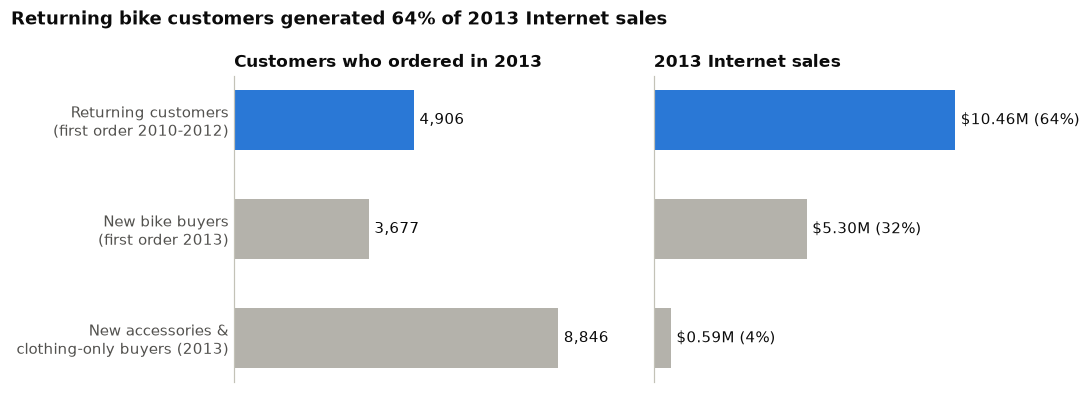

In [29]:
labels = ["Returning customers\n(first order 2010-2012)", "New bike buyers\n(first order 2013)",
          "New accessories &\nclothing-only buyers (2013)"]
colors = [ACCENT, GREY, GREY]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
ypos = np.arange(len(GROUPS))
ax1.barh(ypos, groups_2013["Customers"], color=colors, height=0.55)
ax2.barh(ypos, groups_2013["Sales"] / 1e6, color=colors, height=0.55)
for y, (n, s, share) in enumerate(zip(groups_2013["Customers"], groups_2013["Sales"], groups_2013["ShareOfSales"])):
    ax1.text(n + 150, y, f"{n:,}", va="center", fontsize=10, color=INK)
    ax2.text(s / 1e6 + 0.2, y, f"${s / 1e6:,.2f}M ({share:.0%})", va="center", fontsize=10, color=INK)
ax1.set_yticks(ypos)
ax1.set_yticklabels(labels)
ax1.invert_yaxis()
for ax, title, xmax in [(ax1, "Customers who ordered in 2013", 11000), (ax2, "2013 Internet sales", 14)]:
    ax.set_title(title, fontsize=11, loc="left")
    ax.set_xlim(0, xmax)
    ax.set_xticks([])
    ax.tick_params(axis="y", length=0)
    ax.grid(False)
    ax.spines["bottom"].set_visible(False)
fig.suptitle("Returning bike customers generated 64% of 2013 Internet sales", x=0.01, ha="left",
             fontsize=12, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_2013_sales_by_customer_group.png")
plt.show()

In [30]:
first_dates = orders[orders["OrderNumber"] == 1].set_index("CustomerKey")["OrderDate"]
second = orders[orders["OrderNumber"] == 2].set_index("CustomerKey")
second = second.join(customers[["FirstYear", "FirstOrderHadBike"]])
second["DaysAfterFirst"] = (second["OrderDate"] - first_dates.reindex(second.index)).dt.days

cohorts = customers.groupby(["FirstYear", "FirstOrderHadBike"]).agg(
    Customers=("Sales", "size"), ShareWithSecondOrder=("Orders", lambda s: (s >= 2).mean()),
    ShareThatEverBoughtBike=("BoughtBike", "mean"))
second_stats = second.groupby(["FirstYear", "FirstOrderHadBike"]).agg(
    MedianDaysToSecondOrder=("DaysAfterFirst", "median"), AvgSecondOrder=("Sales", "mean"),
    SecondOrderHasBike=("HasBike", "mean"))
cohorts = cohorts.join(second_stats)
cohorts.style.format({"Customers": "{:,}", "ShareWithSecondOrder": "{:.1%}", "ShareThatEverBoughtBike": "{:.1%}",
                      "MedianDaysToSecondOrder": "{:,.0f}", "AvgSecondOrder": "${:,.2f}",
                      "SecondOrderHasBike": "{:.1%}"}, na_rep="-")

In [31]:
early = customers[customers["FirstYear"] <= 2012]
second_early = second[second["FirstYear"] <= 2012]
print(f"Customers who first bought in 2010-2012: {len(early):,} (all bought a bike on their first order)")
print(f"  placed a second order: {(early['Orders'] >= 2).mean():.1%}")
print(f"  second orders placed on or after 28 Dec 2012, when the expanded range went on sale: "
      f"{(second_early['OrderDate'] >= launch).mean():.1%}")
print(f"  second orders that included a bike: {second_early['HasBike'].mean():.1%}")
print(f"  average second order: ${second_early['Sales'].mean():,.2f}, "
      f"gross margin {second_early['GrossProfit'].sum() / second_early['Sales'].sum():.1%}")

never_bike = customers[~customers["BoughtBike"]]
print(f"\nCustomers who have never bought a bike: {len(never_bike):,} ({len(never_bike) / len(customers):.1%} of customers)")
print(f"  their lifetime sales: ${never_bike['Sales'].sum():,.0f} ({never_bike['Sales'].sum() / customers['Sales'].sum():.1%} of all sales)")
print(f"  average lifetime spend: ${never_bike['Sales'].mean():,.2f}")
converted = customers[~customers["FirstOrderHadBike"] & customers["BoughtBike"]]
print(f"  customers whose first order had no bike but who later bought one: {len(converted)}")

bike_orders_2013 = orders[(orders["Year"] == 2013) & orders["HasBike"]]
add_on_sales = sales.loc[sales["SalesOrderNumber"].isin(bike_orders_2013["SalesOrderNumber"])
                         & sales["Category"].ne("Bikes"), "SalesAmount"].sum()
print(f"\n2013 bike orders: {len(bike_orders_2013):,}")
print(f"  share that also included accessories or clothing: "
      f"{(bike_orders_2013['HasAccessory'] | bike_orders_2013['HasClothing']).mean():.1%}")
print(f"  accessory and clothing sales per bike order: ${add_on_sales / len(bike_orders_2013):,.2f}")

Customers who first bought in 2010-2012: 5,455 (all bought a bike on their first order)
  placed a second order: 90.2%
  second orders placed on or after 28 Dec 2012, when the expanded range went on sale: 100.0%
  second orders that included a bike: 100.0%
  average second order: $1,715.74, gross margin 41.7%

Customers who have never bought a bike: 9,352 (50.6% of customers)
  their lifetime sales: $632,495 (2.2% of all sales)
  average lifetime spend: $67.63
  customers whose first order had no bike but who later bought one: 0

2013 bike orders: 9,706
  share that also included accessories or clothing: 87.6%
  accessory and clothing sales per bike order: $41.75


In [32]:
country_econ = customers.groupby("Country").agg(
    Customers=("Sales", "size"), SalesPerCustomer=("Sales", "mean"), BikeBuyerShare=("BoughtBike", "mean"))
country_econ["NeverBoughtBike"] = customers[~customers["BoughtBike"]].groupby("Country").size()
country_econ["NewBikeBuyers2013"] = customers[(customers["FirstYear"] == 2013) & customers["BoughtBike"]].groupby("Country").size()
country_econ["EarlyBuyersWhoReturned"] = (early.assign(Returned=early["Orders"] >= 2)
                                          .groupby("Country")["Returned"].mean())
country_econ = country_econ.sort_values("Customers", ascending=False)
country_econ.style.format({"Customers": "{:,}", "SalesPerCustomer": "${:,.0f}", "BikeBuyerShare": "{:.1%}",
                           "NeverBoughtBike": "{:,}", "NewBikeBuyers2013": "{:,}", "EarlyBuyersWhoReturned": "{:.1%}"})

,Customers,SalesPerCustomer,BikeBuyerShare,NeverBoughtBike,NewBikeBuyers2013,EarlyBuyersWhoReturned
Country,,,,,,
United States,"7,819","$1,201",45.6%,"4,250","1,932",80.6%
Australia,"3,591","$2,523",60.0%,"1,436",253,99.8%
United Kingdom,"1,913","$1,773",53.9%,881,457,99.1%
France,"1,810","$1,461",45.1%,994,321,90.1%
Germany,"1,780","$1,626",50.8%,876,396,96.7%
Canada,"1,571","$1,259",41.8%,915,318,58.3%


**What drives growth.**

- **Repeat bike buyers drove 2013.** Customers who first bought in 2010–2012 produced **\$10.46M, or 64.0% of 2013 sales**. Of the 5,455 customers who bought their first bike in 2010–2012, 90.2% came back. Every one of their second orders was placed on or after 28 December 2012, when the expanded range went on sale, and every second order included another bike (average order \$1,715.74).
- **That wave is largely spent.** Nine in ten early customers have already made their second purchase. 2014 depends on the **3,677 customers who bought their first bike in 2013**: only 2.2% have returned so far, but earlier cohorts took a median of 368 days (2012 cohort) to 673 days (2011 cohort) to come back.
- **Accessories brought traffic, not bike buyers.** 8,846 new 2013 customers bought only accessories or clothing (\$66 each). None of the 9,352 customers whose first order had no bike has ever bought one.
- **Bike orders already carry add-ons.** 87.6% of 2013 bike orders included accessories or clothing, but only \$41.75 per order. Accessories earn a 62.6% gross margin.
- **The United States has the most room to grow.** It has the most customers (7,819) but the lowest sales per customer (\$1,201, against \$2,523 in Australia). It also has the most customers who have never bought a bike (4,250) and the most 2013 first-time bike buyers (1,932). Its early buyers came back less often (80.6%) than in Australia (99.8%), the United Kingdom (99.1%) or Germany (96.7%).

## 10. Who buys bikes?

Bike buyers are worth about 46 times as much as customers who buy only accessories (\$3,146 against \$68 in lifetime sales), so it matters which customer profiles buy bikes.

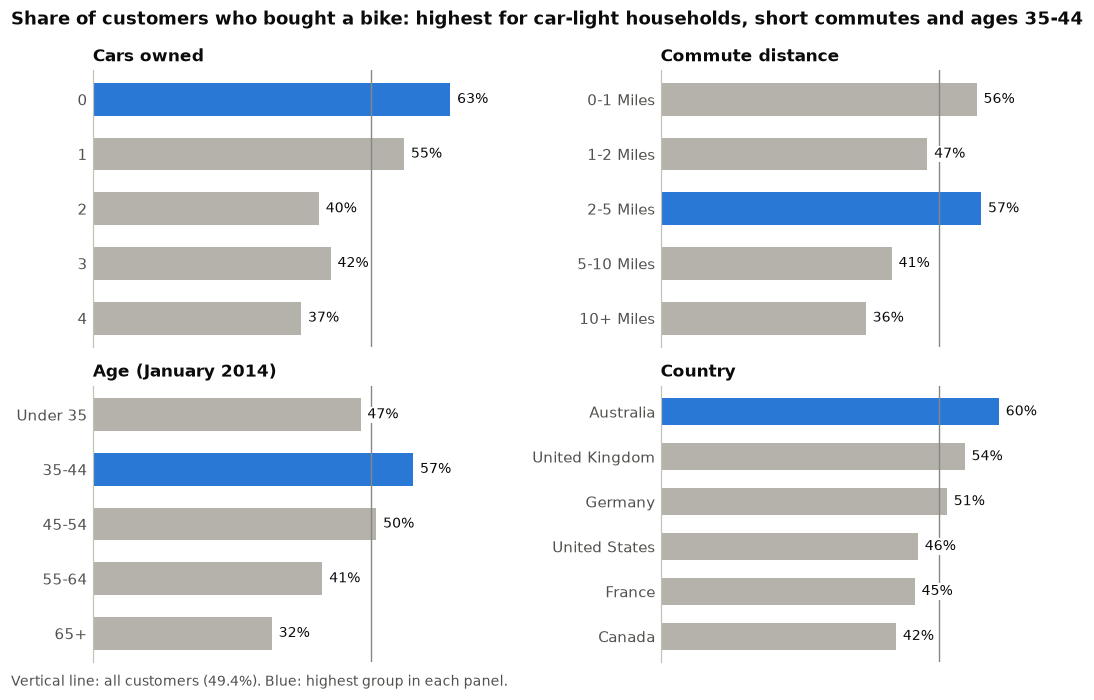

In [33]:
customers["AgeBand"] = pd.cut(customers["Age"], bins=[0, 34, 44, 54, 64, 120],
                              labels=["Under 35", "35-44", "45-54", "55-64", "65+"])
commute_order = ["0-1 Miles", "1-2 Miles", "2-5 Miles", "5-10 Miles", "10+ Miles"]
panels = {
    "Cars owned": customers.groupby("NumberCarsOwned")["BoughtBike"].mean(),
    "Commute distance": customers.groupby("CommuteDistance")["BoughtBike"].mean().reindex(commute_order),
    "Age (January 2014)": customers.groupby("AgeBand", observed=True)["BoughtBike"].mean(),
    "Country": customers.groupby("Country")["BoughtBike"].mean().sort_values(ascending=False),
}
overall_rate = customers["BoughtBike"].mean()

fig, axes = plt.subplots(2, 2, figsize=(10, 6.2))
for ax, (title, rates) in zip(axes.flat, panels.items()):
    ypos = np.arange(len(rates))
    ax.barh(ypos, rates.to_numpy(), color=[ACCENT if r == rates.max() else GREY for r in rates], height=0.6)
    ax.axvline(overall_rate, color="#898781", linewidth=0.9)
    for yy, r in zip(ypos, rates.to_numpy()):
        ax.text(r + 0.012, yy, f"{r:.0%}", va="center", fontsize=9, color=INK,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.8))
    ax.set_yticks(ypos)
    ax.set_yticklabels([str(i) for i in rates.index])
    ax.tick_params(axis="y", length=0)
    ax.invert_yaxis()
    ax.set_xlim(0, 0.75)
    ax.set_xticks([])
    ax.grid(False)
    ax.spines["bottom"].set_visible(False)
    ax.set_title(title, fontsize=11, loc="left")
fig.suptitle("Share of customers who bought a bike: highest for car-light households, short commutes and ages 35-44",
             x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
fig.text(0.01, -0.01, f"Vertical line: all customers ({overall_rate:.1%}). Blue: highest group in each panel.",
         fontsize=9, color=MUTED)
fig.tight_layout()
fig.savefig(FIG_DIR / "figA1_bike_buyer_profile.png")
plt.show()

Bike buyers are concentrated among customers with **no car (63%) or one car (55%)**, **short commutes** (56% for 0–1 mile and 57% for 2–5 miles), **ages 35–44 (57%)** and **Australia (60%)**. Customers with four cars (37%), commutes over 10 miles (36%) or aged 65+ (32%) rarely buy bikes. These profiles, not home ownership, are the useful targeting variables.

## 11. Sizing the recommendation

The recommended strategy (see the report) has three levers. Each is sized from behavior observed in this data:

| Lever | Customers it applies to | Value per success | Basis in the data |
|---|---|---|---|
| Second-bike program for 2013 first-time bike buyers | 3,677 | average second order of earlier bike buyers | 90.2% of 2010–12 bike buyers returned |
| Convert never-bike customers to a first bike | 9,352 | average bike price | none has converted so far, so rates are deliberately low |
| Bundle accessories into bike orders | about 9,700 bike orders a year | extra add-on spend per order | \$41.75 per bike order today |

The scenarios are illustrative. The data cannot show how much of this would happen without the program, so results should be measured against a control group.

In [34]:
bike_cohort_2013 = int(((customers["FirstYear"] == 2013) & customers["BoughtBike"]).sum())
never_bike_customers = len(never_bike)
second_bike_value = second_early["Sales"].mean()
second_bike_margin = second_early["GrossProfit"].sum() / second_early["Sales"].sum()
bike_margin = category_summary.loc["Bikes", "GrossMargin"]
non_bike = sales[sales["Category"] != "Bikes"]
add_on_margin = non_bike["GrossProfit"].sum() / non_bike["SalesAmount"].sum()
bike_orders_per_year = len(bike_orders_2013)

scenarios = pd.DataFrame({
    "SecondBikeRate": [0.40, 0.60, 0.90],
    "ConversionRate": [0.02, 0.05, 0.10],
    "ExtraAddOnPerBikeOrder": [10, 20, 30],
}, index=["Conservative", "Moderate", "Strong"])
scenarios["SecondBikeSales"] = bike_cohort_2013 * scenarios["SecondBikeRate"] * second_bike_value
scenarios["ConversionSales"] = never_bike_customers * scenarios["ConversionRate"] * avg_price
scenarios["BundleSales"] = bike_orders_per_year * scenarios["ExtraAddOnPerBikeOrder"]
scenarios["TotalSales"] = scenarios[["SecondBikeSales", "ConversionSales", "BundleSales"]].sum(axis=1)
scenarios["GrossProfit"] = (scenarios["SecondBikeSales"] * second_bike_margin
                            + scenarios["ConversionSales"] * bike_margin
                            + scenarios["BundleSales"] * add_on_margin)
scenarios["ShareOf2013Sales"] = scenarios["TotalSales"] / country_year.loc["Total", 2013]

print(f"Inputs: {bike_cohort_2013:,} first-time bike buyers in 2013; {never_bike_customers:,} never-bike customers; "
      f"{bike_orders_per_year:,} bike orders in 2013")
print(f"Second order ${second_bike_value:,.2f} at {second_bike_margin:.1%} margin; bike ${avg_price:,.2f} at "
      f"{bike_margin:.1%}; add-ons at {add_on_margin:.1%}")
money = "${:,.0f}"
scenarios.style.format({"SecondBikeRate": "{:.0%}", "ConversionRate": "{:.0%}", "ExtraAddOnPerBikeOrder": "${:,.0f}",
                        "SecondBikeSales": money, "ConversionSales": money, "BundleSales": money,
                        "TotalSales": money, "GrossProfit": money, "ShareOf2013Sales": "{:.1%}"})

Inputs: 3,677 first-time bike buyers in 2013; 9,352 never-bike customers; 9,706 bike orders in 2013
Second order $1,715.74 at 41.7% margin; bike $1,862.42 at 40.6%; add-ons at 55.3%


,SecondBikeRate,ConversionRate,ExtraAddOnPerBikeOrder,SecondBikeSales,ConversionSales,BundleSales,TotalSales,GrossProfit,ShareOf2013Sales
Conservative,40%,2%,$10,"$2,523,503","$348,348","$97,060","$2,968,911","$1,248,687",18.2%
Moderate,60%,5%,$20,"$3,785,255","$870,869","$194,120","$4,850,244","$2,041,387",29.7%
Strong,90%,10%,$30,"$5,677,882","$1,741,738","$291,180","$7,710,800","$3,239,000",47.2%


## 12. Summary of answers

In [35]:
print("Q1. Internet sales by year (full years):")
for yr in FULL_YEARS:
    print(f"    {yr}: ${country_year.loc['Total', yr]:,.0f}")
print(f"    Largest markets: United States ${country_year.loc['United States', 'Total']:,.0f}, "
      f"Australia ${country_year.loc['Australia', 'Total']:,.0f}")
print(f"Q2. Mean yearly income ranges from ${income_country['Mean'].min():,.0f} (France) to "
      f"${income_country['Mean'].max():,.0f} (Australia); gender gaps within a country are under $2,000.")
print(f"Q3. {top_category} produce {category_summary.loc[top_category, 'ShareOfSales']:.1%} of sales; "
      f"average price ${avg_price:,.2f} per bike.")
print(f"Q4. Homeowners spend ${diff:,.2f} more per customer (p < 0.001, Cohen's d = {diff / pooled_sd:.2f}); "
      f"with controls about ${owner['Coef']:,.0f}. Statistically significant, commercially small.")
print(f"Growth: returning customers produced {groups_2013.loc[GROUPS[0], 'ShareOfSales']:.0%} of 2013 sales; "
      f"{bike_cohort_2013:,} first-time 2013 bike buyers are the next repeat wave.")

Q1. Internet sales by year (full years):
    2011: $7,075,526
    2012: $5,842,485
    2013: $16,351,550
    Largest markets: United States $9,389,790, Australia $9,061,001
Q2. Mean yearly income ranges from $35,762 (France) to $64,339 (Australia); gender gaps within a country are under $2,000.
Q3. Bikes produce 96.5% of sales; average price $1,862.42 per bike.
Q4. Homeowners spend $130.51 more per customer (p < 0.001, Cohen's d = 0.06); with controls about $110. Statistically significant, commercially small.
Growth: returning customers produced 64% of 2013 sales; 3,677 first-time 2013 bike buyers are the next repeat wave.
